B.1 Produrre, utilizzando la formula semiempirica di massa e tramite calcolatore, il grafico delle masse atomiche in
funzione di Z, selezionando un valore di A a vostra scelta. Ripetere l'operazione per il valore A + 1. Confrontare la
previsione del modello con i dati sperimentali reperibili sul web.

In [2]:
import sys
print(sys.executable)

/home/gea/TD/.venv/bin/python


In [3]:
import matplotlib.pyplot as plt
import numpy as np

# per mettere i tick sugli interi nel plot
from matplotlib.ticker import MultipleLocator

In [4]:
# Constants

c = 1 # unità naturali
mp = 938.272089 # MeV
mn = 939.565422 # MeV 
u = 931.5 # Mev

# coeffs
av, a_s, ac, aa, ap = 15.56, 17.23, 0.697, 23.28, 12.0
# av, a_s, ac, aa, ap = 15.75, 17.8, 0.711, 23.7, 12.0

In [1]:
### Formule ###

def delta(N, Z):
    result = []

    for n, z in zip(N, Z):
        if n % 2 == 0 and z % 2 == 0:
            result.append(1)
        elif n % 2 == 1 and z % 2 == 1:
            result.append(-1)
        else:
            result.append(0)

    return np.array(result)

    
def B(A,Z, segno):
    N = A-Z
    if segno==None:
        segno = delta(N, Z)
        
    return av*A  \
        - a_s * A**(2/3) \
        - ac *Z*(Z-1)/A**(1/3) \
        - aa *(N-Z)**2/A \
        + segno * ap/A**(1/2)

def M(A,Z, segno=None):
    '''Trascuro Be, energia di legame degli elettroni'''  
    N = A-Z
    return Z * (mp + me) + N * mn -B(A,Z,segno)/(c**2)

In [ ]:
# Cosa plottare

A = 206
Z = np.linspace(72, 92, 21)
z = np.linspace(72, 92, 100)
# Z = np.linspace(int(A/2)-10, int(A/2)+6, 17)
# z = np.linspace(int(A/2)-10, int(A/2)+6, 1000)

A = 206
Z = np.linspace(72, 92, 21)
z = np.linspace(72, 92, 100)

In [17]:
print(Z)

[72. 73. 74. 75. 76. 77. 78. 79. 80. 81. 82. 83. 84. 85. 86. 87. 88. 89.
 90. 91. 92.]


In [18]:
# plot

def plot_parabole(ax, A):
    if A%2==1:
        ax.plot(z, M(A,z), linewidth=2, color = 'gray', label="PD")  # completa la linea, magari tratteggiata???
    else:
        ax.plot(z, M(A,z, segno=1), linewidth=2, color = 'violet', label="PP")  # completa la linea, magari tratteggiata???
        ax.plot(z, M(A,z, segno=-1), linewidth=2, color = 'gray', label="DD")  # completa la linea, magari tratteggiata???
    return

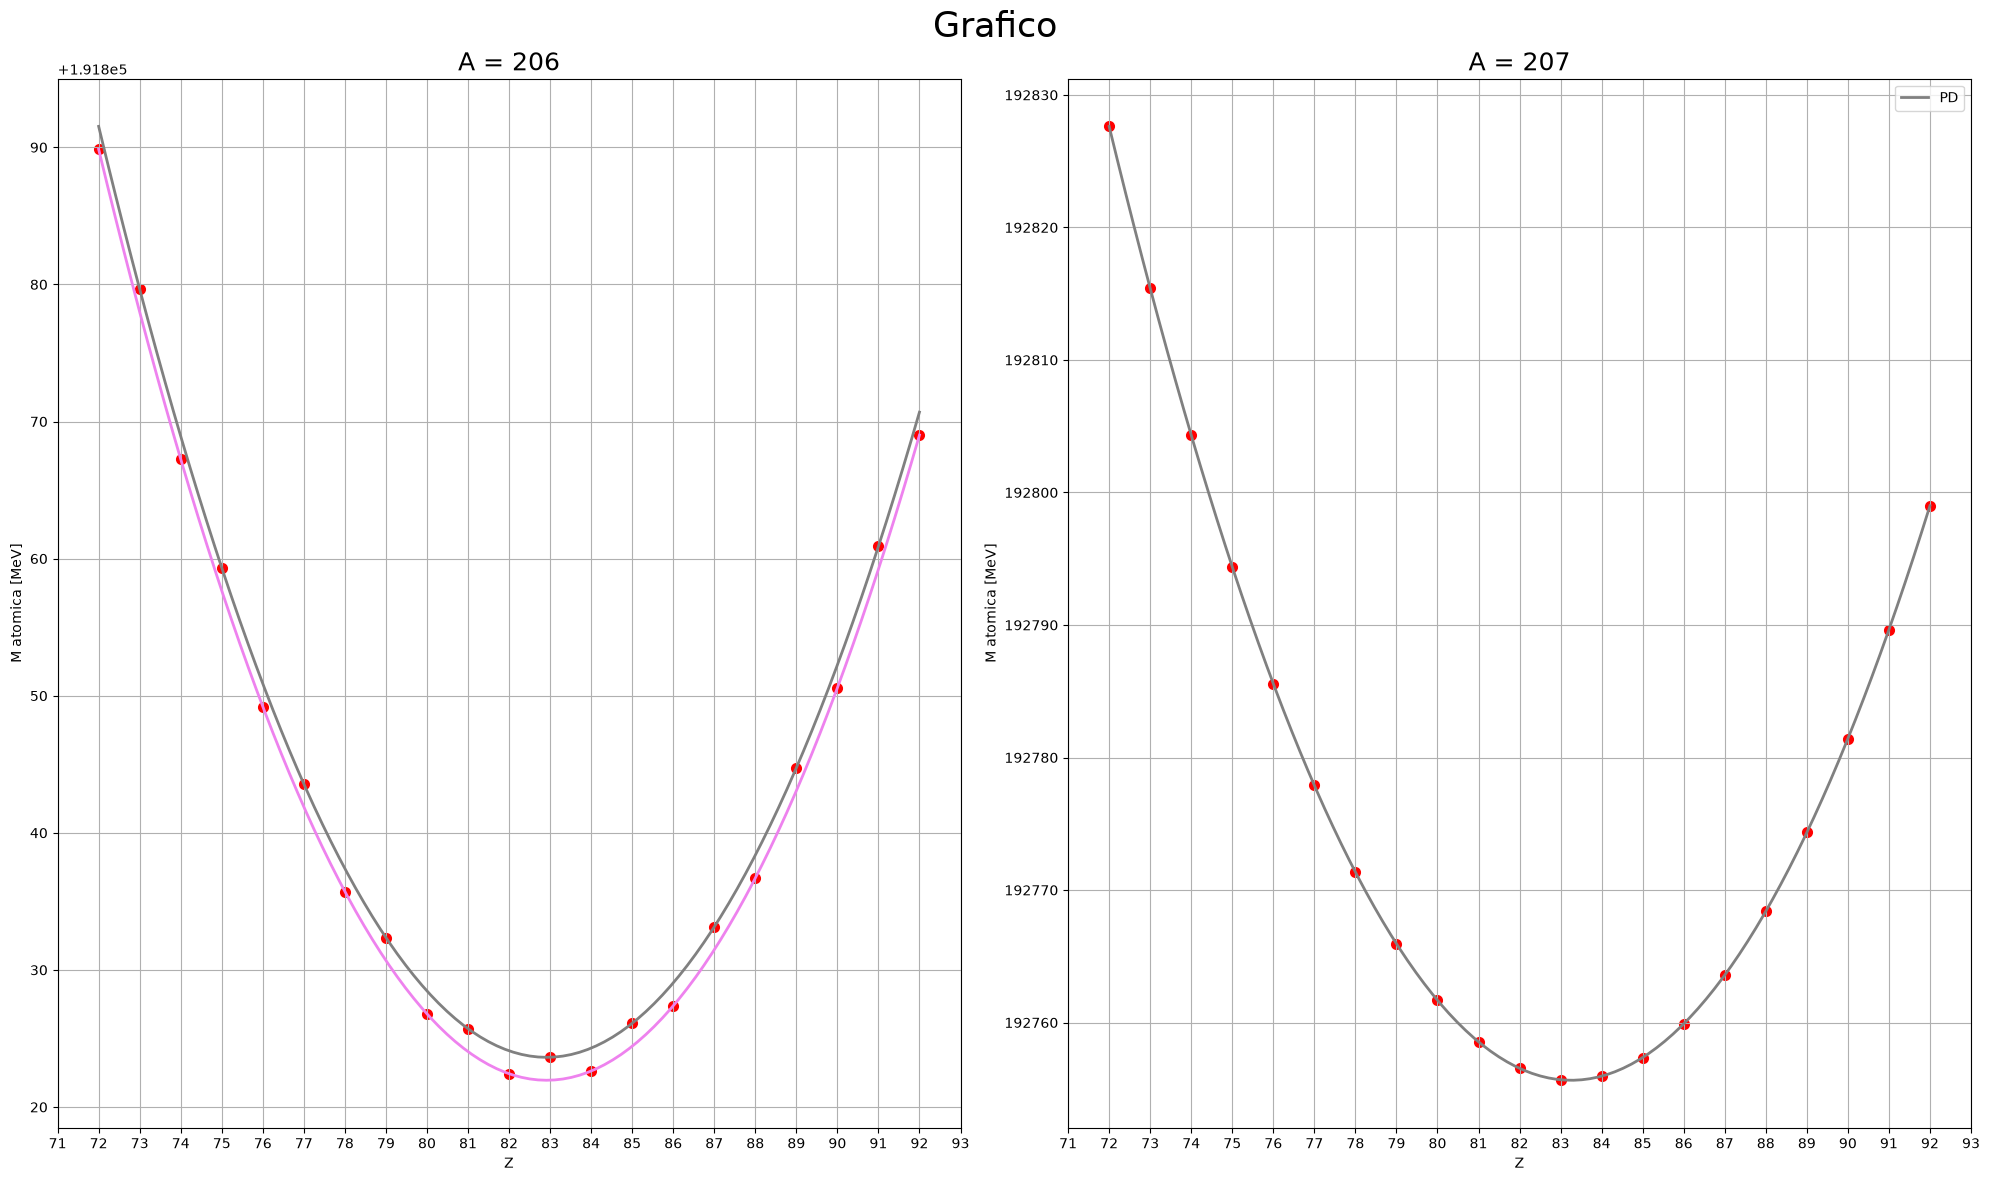

In [19]:
# Plot
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(20, 12))

fig.suptitle( "Grafico", fontsize=25)

ax1.scatter(Z, M(A,Z), linewidth=2, label="Atomi", color='red')
ax1.set_xlabel("Z")
ax1.set_ylabel("M atomica [MeV]")
plot_parabole(ax1, A)
ax1.xaxis.set_major_locator(MultipleLocator(1))
ax1.grid(True, which="both")
ax1.set_title(f"A = {A}", fontsize=18)

ax2.scatter(Z, M(A+1,Z), linewidth=2, color='red')
plot_parabole(ax2, A+1)
ax2.set_xlabel("Z")
ax2.set_ylabel("M atomica [MeV]")
ax2.grid(True, which="both")
ax2.xaxis.set_major_locator(MultipleLocator(1))
ax2.set_title(f"A = {A+1}", fontsize=18)
ax2.legend()

fig.tight_layout()
plt.show()

1- CENTRARE IL GRAFICO nel minimo dela parabola  
ma poi, plotta abbastanza punti per vedere Z/2  
fallo calcolando la distanza tra Z/2 e la Z dell'atomo alla punta (formula con la piccola correzione)  


2- 
METTERE UNA LINEA VERTICALE A Z/2  
E UNA ALL'ATOMO STABILE  

### Sol

56 Cr 55.94065310 55.93540070 -4.893 MeV
56 Mn 55.93890369 55.93485870 -3.768 MeV
56 Fe 55.93493633 55.93146443 -3.234 MeV
56 Co 55.93983880 55.93898989 -0.791 MeV
56 Ni 55.94212855 55.94366308 +1.429 MeV
Minimo modello: 56 26
RMSE (MeV): 3.2019311164622595
57 Cr 56.94361300 56.93862907 -4.642 MeV
57 Mn 56.93828610 56.93302545 -4.900 MeV
57 Fe 56.93539284 56.93138944 -3.729 MeV
57 Co 56.93629057 56.93372105 -2.393 MeV
57 Ni 56.93979218 56.94002027 +0.212 MeV
Minimo modello: 57 26
RMSE (MeV): 3.6123619210989504


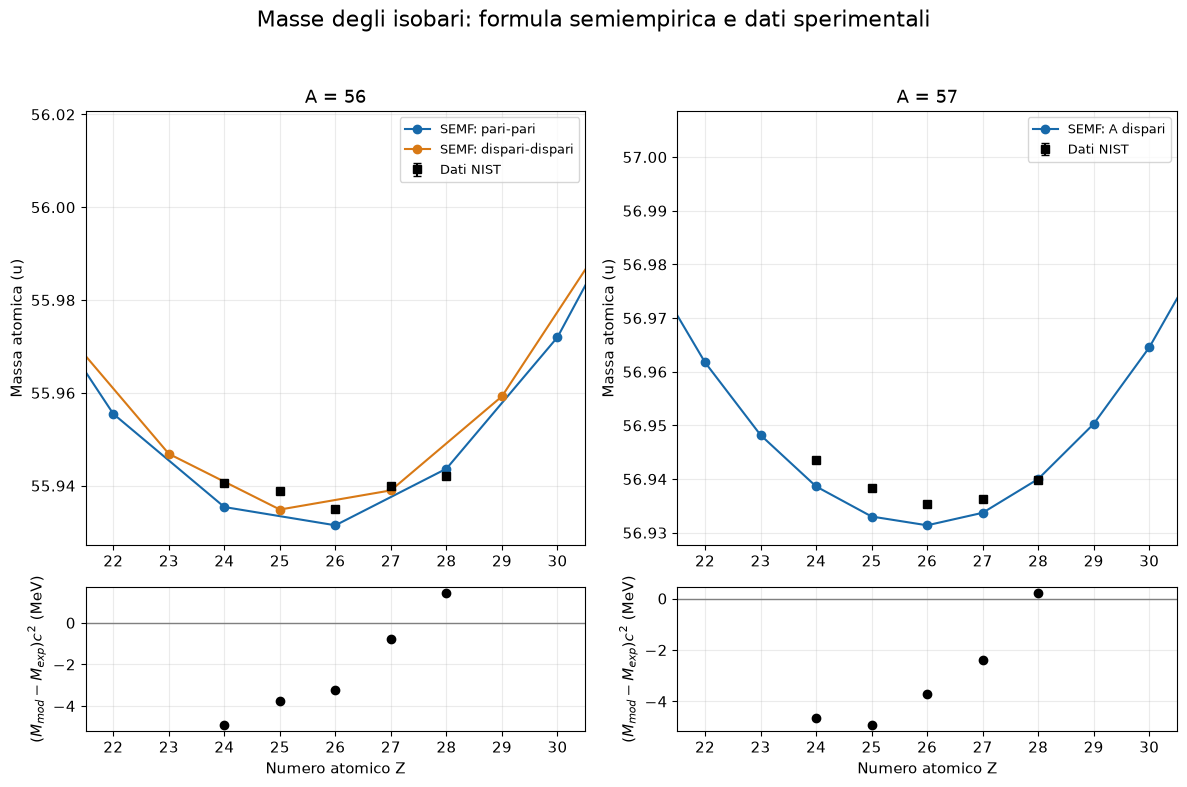

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import csv
from pathlib import Path 

# Coefficienti in MeV: una parametrizzazione comune della SEMF.
av, a_s, ac, aa, ap = 15.75, 17.8, 0.711, 23.7, 12.0
# Masse in u; si trascura il legame degli elettroni atomici.
mH, mn, uc2 = 1.00782503223, 1.00866491595, 931.49410242
# Dati NIST: https://physics.nist.gov/cgi-bin/Compositions/stand_alone.pl?ele=&isotype=all
Zexp = np.arange(24, 29)
symbols = ['Cr', 'Mn', 'Fe', 'Co', 'Ni']
experimental = {
    56: np.array([55.9406531, 55.93890369, 55.93493633, 55.93983880, 55.94212855]),
    57: np.array([56.9436130, 56.9382861, 56.93539284, 56.93629057, 56.93979218])
}
errors = {
    56: np.array([2e-6, 4.9e-7, 4.9e-7, 6.3e-7, 5.7e-7]),
    57: np.array([2e-6, 1.6e-6, 4.9e-7, 6.6e-7, 7.1e-7])
}

def binding(A, Z):
    Z = np.asarray(Z)
    if A % 2:
        delta = np.zeros_like(Z, dtype=float)
    else:
        delta = np.where(Z % 2 == 0, ap / np.sqrt(A), -ap / np.sqrt(A))
    return av*A - a_s*A**(2/3) - ac*Z*(Z-1)/A**(1/3) - aa*(A-2*Z)**2/A + delta

def mass(A, Z):
    return Z*mH + (A-Z)*mn - binding(A, Z)/uc2

plt.rcParams.update({'font.size': 11, 'axes.formatter.useoffset': False})
fig, axes = plt.subplots(2, 2, figsize=(12, 8), gridspec_kw={'height_ratios':[3, 1]})
rows = []
for col, A in enumerate([56, 57]):
    ax, res = axes[0, col], axes[1, col]
    if A % 2 == 0:
        for parity, color, label in [(0, '#1769aa', 'SEMF: pari-pari'), (1, '#d87915', 'SEMF: dispari-dispari')]:
            z = np.arange(20 + parity, 33, 2)
            ax.plot(z, mass(A, z), 'o-', color=color, label=label)
    else:
        z = np.arange(20, 33)
        ax.plot(z, mass(A, z), 'o-', color='#1769aa', label='SEMF: A dispari')
    ax.errorbar(Zexp, experimental[A], yerr=errors[A], fmt='ks', capsize=3, label='Dati NIST', zorder=5)
    ax.set(title=f'A = {A}', ylabel='Massa atomica (u)', xlim=(21.5, 30.5))
    ax.legend(fontsize=9)
    ax.grid(alpha=.25)
    residual = (mass(A, Zexp)-experimental[A])*uc2
    res.errorbar(Zexp, residual, yerr=errors[A]*uc2, fmt='ko', capsize=3)
    res.axhline(0, color='gray', lw=1)
    res.set(xlabel='Numero atomico Z', ylabel=r'$(M_{mod}-M_{exp})c^2$ (MeV)', xlim=(21.5, 30.5))
    res.grid(alpha=.25)
    for z, s, me, mt, rr in zip(Zexp, symbols, experimental[A], mass(A, Zexp), residual):
        rows.append([A, int(z), s, f'{me:.8f}', f'{mt:.8f}', f'{rr:.3f}'])
        print(A, s, f'{me:.8f}', f'{mt:.8f}', f'{rr:+.3f} MeV')
    allz = np.arange(1, A)
    print('Minimo modello:', A, int(allz[np.argmin(mass(A, allz))]))
    print('RMSE (MeV):', np.sqrt(np.mean(residual**2)))
fig.suptitle('Masse degli isobari: formula semiempirica e dati sperimentali', fontsize=16)
fig.tight_layout(rect=[0, 0, 1, .95])
fig.savefig('masse_isobari.png', dpi=180)
with open('confronto_masse.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['A', 'Z', 'Elemento', 'M_exp_u', 'M_SEMF_u', 'Scarto_MeV'])
    writer.writerows(rows)
plt.show()

In [21]:
# Prendi dati dal database

import re
from io import StringIO

import numpy as np
import pandas as pd
import requests


def atomic_mass(A, Z):
    
    '''
    """Return NIST atomic masses in u; missing isotopes return np.nan."""
    A = np.asarray(A)
    Z = np.asarray(Z)

    if A.ndim != 1 or Z.ndim != 1 or A.shape != Z.shape:
        raise ValueError("A and Z must be 1D arrays of the same length.")

    for values in (A, Z):
        if not np.all(np.isfinite(values) & (values == np.floor(values))):
            raise ValueError("A and Z must contain finite integers.")

    if np.any(Z < 1) or np.any(A < Z):
        raise ValueError("Require A >= Z >= 1.")
    '''

    url = (
        "https://physics.nist.gov/cgi-bin/Compositions/"
        "stand_alone.pl?ele=&isotype=all"
    )
    response = requests.get(
        url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30
    )
    response.raise_for_status()

    tables = pd.read_html(StringIO(response.text))
    masses = {}

    for table in tables:
        if table.shape[1] < 4:
            continue

        # Columns: Z, element symbol, A, relative atomic mass, ...
        atomic_numbers = pd.to_numeric(
            table.iloc[:, 0], errors="coerce"
        ).ffill()
        mass_numbers = pd.to_numeric(table.iloc[:, 2], errors="coerce")

        for z, a, value in zip(
            atomic_numbers, mass_numbers, table.iloc[:, 3]
        ):
            if pd.isna(z) or pd.isna(a):
                continue

            # "55.934 936 33(49)" -> "55.93493633"
            value = re.sub(r"\s+", "", str(value)).split("(")[0]
            if re.fullmatch(r"\d+(?:\.\d+)?", value):
                masses[(int(a), int(z))] = float(value)

    if not masses:
        raise RuntimeError("Could not read the NIST isotope table.")

    return np.array([
        masses.get((int(a), int(z)), np.nan)
        for a, z in zip(A, Z)
    ])

    

In [22]:
A = np.array([56, 56, 57])
Z = np.array([26, 28, 26])  # Fe-56, Ni-56, Fe-57

M_u = atomic_mass(A, Z)
print(M_u)

# Atomic rest energies in MeV, for comparison with your model:
M_MeV = M_u * 931.49410242

ImportError: `Import lxml` failed.  Use pip or conda to install the lxml package.